In [11]:
'''
Assignment 2
Student Name: Aaron Baggot  
Student Number: C22716399 
Module: IDSP1701
TU856/4  

Parameters description:

'''

'\nAssignment 2\nStudent Name: Aaron Baggot  \nStudent Number: C22716399 \nModule: IDSP1701\nTU856/4  \n\nParameters description:\n\n'

In [12]:
import sys, subprocess, importlib
try:
    import matplotlib
    print("matplotlib:", matplotlib.__version__)
except ModuleNotFoundError:
    print("matplotlib not found in this kernel (installing into:", sys.executable, ")")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    matplotlib = importlib.import_module("matplotlib")
    print("Installed matplotlib", matplotlib.__version__)


matplotlib: 3.10.7


In [13]:
from pathlib import Path
import cv2 as cv
import numpy as np
import os
import matplotlib.pyplot as plt


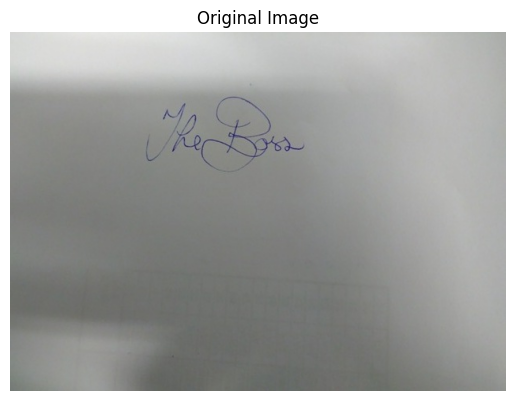

In [14]:
#img_path = Path("signatures.jpg")
img_path = Path("boss.png")

img = cv.imread(str(img_path))

if img is None:
    raise FileNotFoundError("Image not found")

# Display Original Image
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')
plt.show()

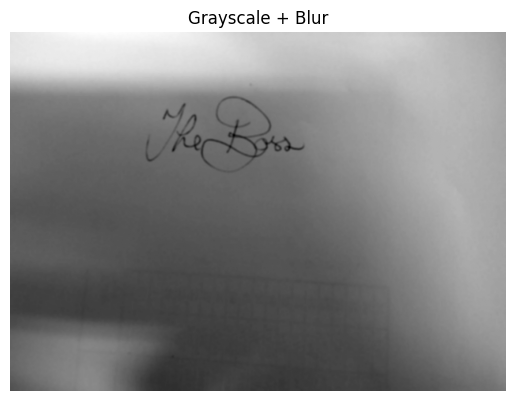

In [15]:
# convert to Grayscale and blur
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (5,5), 0)

plt.imshow(blur, cmap='gray')
plt.title("Grayscale + Blur")
plt.axis('off')
plt.show()

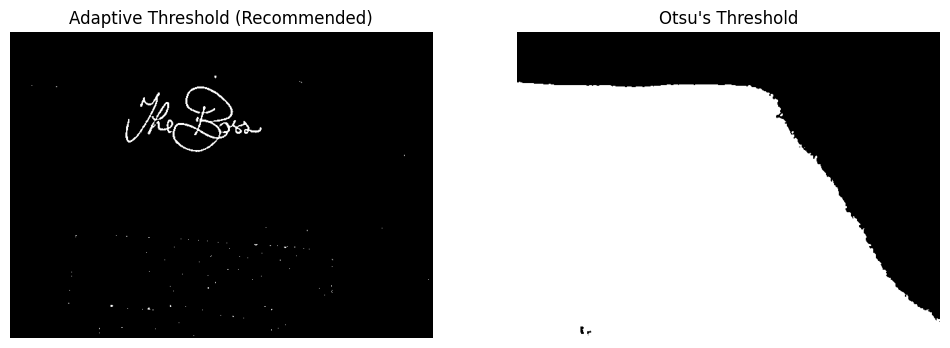

In [16]:
# Threshold to extract signature - try adaptive threshold (more robust to lighting)
# Adaptive threshold works better on images with varying illumination
binary = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                              cv.THRESH_BINARY_INV, blockSize=11, C=2)

# Optional: compare with Otsu's threshold
_, binary_otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

# Display comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(binary, cmap='gray')
axes[0].set_title("Adaptive Threshold (Recommended)")
axes[0].axis('off')
axes[1].imshow(binary_otsu, cmap='gray')
axes[1].set_title("Otsu's Threshold")
axes[1].axis('off')
plt.show()

# If adaptive result is all black, try Otsu instead (uncomment to toggle)
# binary = binary_otsu

Adaptive threshold: blockSize=11, C=2
Results:
  - White pixels (signature): 2596
  - Black pixels (background): 282062


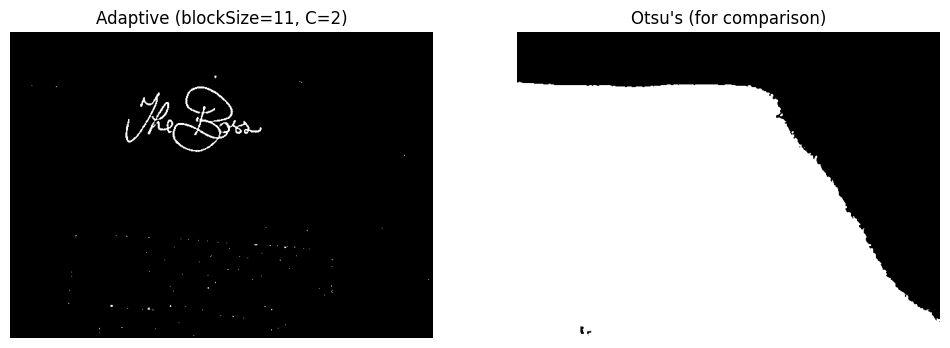

In [17]:
# TUNING: Adjust adaptive threshold parameters
# blockSize: must be odd, larger = considers larger neighborhood (try 9, 11, 13, 15)
# C: constant subtracted from mean (try 0, 1, 2, 3, 4, 5)
# Decrease blockSize if strokes are thin; decrease C if background bleeds in
# Increase blockSize if too much noise; increase C if strokes disappear

blockSize = 11  # <- ADJUST THIS (must be odd)
C = 2           # <- ADJUST THIS (try 0-5)

binary = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                              cv.THRESH_BINARY_INV, blockSize=blockSize, C=C)

print(f"Adaptive threshold: blockSize={blockSize}, C={C}")
print("Results:")
print(f"  - White pixels (signature): {np.sum(binary == 255)}")
print(f"  - Black pixels (background): {np.sum(binary == 0)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(binary, cmap='gray')
axes[0].set_title(f"Adaptive (blockSize={blockSize}, C={C})")
axes[0].axis('off')
axes[1].imshow(binary_otsu, cmap='gray')
axes[1].set_title("Otsu's (for comparison)")
axes[1].axis('off')
plt.show()


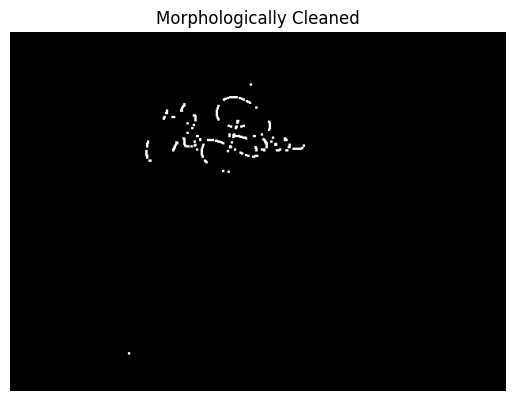

In [18]:
# Morphological Cleaning
kernel = np.ones((3,3), np.uint8)
clean = cv.morphologyEx(binary, cv.MORPH_OPEN, kernel, iterations=1)

plt.imshow(clean, cmap='gray')
plt.title("Morphologically Cleaned")
plt.axis('off')
plt.show()

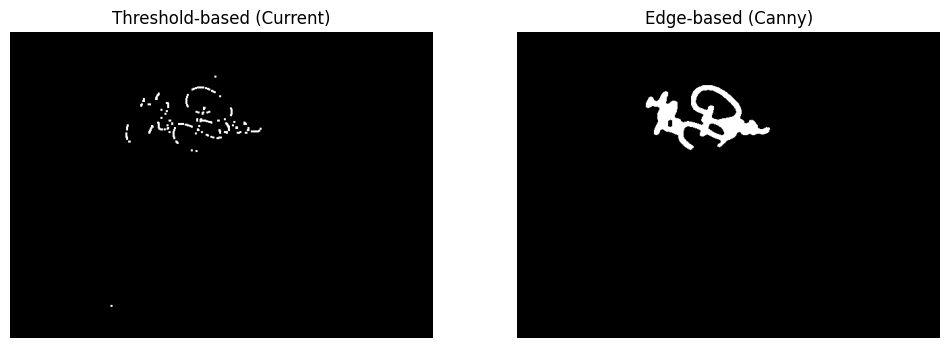

In [19]:
# OPTIONAL: Edge-based segmentation (Canny) - alternative if threshold fails
# This detects stroke edges and may work better on difficult images
edges = cv.Canny(blur, 50, 150)
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
edges_closed = cv.morphologyEx(edges, cv.MORPH_CLOSE, kernel, iterations=2)
edges_filled = cv.dilate(edges_closed, kernel, iterations=1)

# Compare threshold vs edge-based
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(clean, cmap='gray')
axes[0].set_title("Threshold-based (Current)")
axes[0].axis('off')
axes[1].imshow(edges_filled, cmap='gray')
axes[1].set_title("Edge-based (Canny)")
axes[1].axis('off')
plt.show()

# To use edge-based approach instead, uncomment: clean = edges_filled

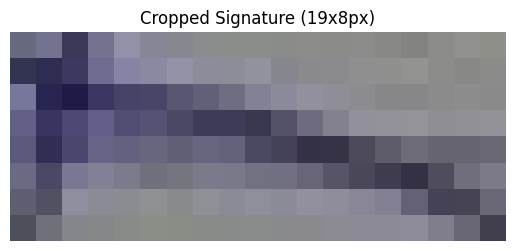

In [20]:
# Crop the Signature region
contours, _ = cv.findContours(clean, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

if len(contours) == 0:
    print("ERROR: No contours found in cleaned image!")
    print("This usually means the threshold produced all-white or all-black.")
    print("Try adjusting:")
    print("  - Cell 6: Use Otsu's threshold instead (uncomment toggle)")
    print("  - Cell 7: Try edge-based Canny detection (uncomment toggle)")
    print("  - Cell 5: Change adaptive threshold blockSize or C parameter")
    plt.imshow(clean, cmap='gray')
    plt.title("Cleaned Image (No contours detected)")
    plt.show()
else:
    largest_contour = max(contours, key=cv.contourArea)
    x, y, w, h = cv.boundingRect(largest_contour)
    
    # Validate crop region
    if w > 0 and h > 0:
        cropped = img[y:y+h, x:x+w].copy()
        plt.imshow(cv.cvtColor(cropped, cv.COLOR_BGR2RGB))
        plt.title(f"Cropped Signature ({w}x{h}px)")
        plt.axis('off')
        plt.show()
    else:
        print("ERROR: Invalid crop region dimensions!")
        print(f"Width: {w}, Height: {h}")


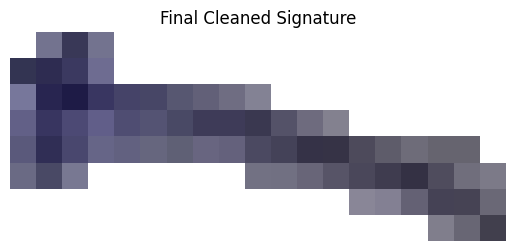

Signature saved as: /Users/aaronbaggot/Desktop/Assignment_2_Segmentation/Cleaned_Signature.png


In [21]:
# Set white background and save image
# Replace background with white

# Check if cropped region exists
if 'cropped' not in locals() or cropped.size == 0:
    print("ERROR: Cropped image not available. Run the previous cell first and fix any issues.")
else:
    mask = cv.cvtColor(clean[y:y+h, x:x+w], cv.COLOR_GRAY2BGR)
    white_bg = np.ones_like(cropped, np.uint8) * 255
    signature = np.where(mask == 0, white_bg, cropped)

    # Save cleaned Signature
    output_path = Path("Cleaned_Signature.png")
    cv.imwrite(str(output_path), signature)

    plt.imshow(cv.cvtColor(signature, cv.COLOR_BGR2RGB))
    plt.title("Final Cleaned Signature")
    plt.axis('off')
    plt.show()

    print(f"Signature saved as: {output_path.resolve()}")


In [ ]:
#take out CLAHE

In [54]:
# Boost the blue contrast so blue signature will stand out before thresholding
# Lab colour space

In [67]:
# Segmentation on 
# lab_enh = cv2.cvtColor(lab_eq, cv2.COLOR_RGB2LAB) #enhanced
#     l_enh, a_enh, b_enh = cv2.split(lab_enh)

#     #Segmentation
#     _, fish_thresh = cv2.threshold(b_enh, 100, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
#     fish_thresh = cv2.bitwise_not(fish_thresh) #invert the mask

In [ ]:
# blur
# adaptive
# invert
# liptical kernal
# opening closing dialiation
# contours
# largest contour = max contour, key=cv.contour
# bounding box - rectangle from features
# convert to binary image
# Sharpen


In [ ]:
# Extra reading for original authors and design to cite